# DSCI 552 - Homework 5

Decision trees and regression models. I used the data provided with the assignment.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

DATA = Path('data') if Path('data').exists() else Path('.')
RANDOM_STATE = 42

## 1. Decision trees as interpretable models

### (a) Load the acute inflammations data

In [2]:
names = ['temperature','nausea','lumbar_pain','urine_pushing','micturition_pains','burning_urethra','bladder_inflammation','renal_pelvis_nephritis']
diagnosis = pd.read_csv(DATA / 'diagnosis.data', sep=r'\s+', header=None, names=names, encoding='utf-16', engine='python')
diagnosis['temperature'] = pd.to_numeric(diagnosis['temperature'].astype(str).str.replace(',', '.', regex=False))
for c in names[1:]:
    diagnosis[c] = diagnosis[c].astype(str).str.strip().str.lower().map({'yes':1,'no':0})
print(diagnosis.shape)
display(diagnosis.head())
print('Missing values:', diagnosis.isna().sum().sum())

(120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,renal_pelvis_nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


Missing values: 0


### (b) Fit and plot a decision tree using the full dataset

Both diagnosis columns are labels, so I fit a multi-output classification tree.

Training accuracy: 1.0
Leaves: 6 Depth: 4


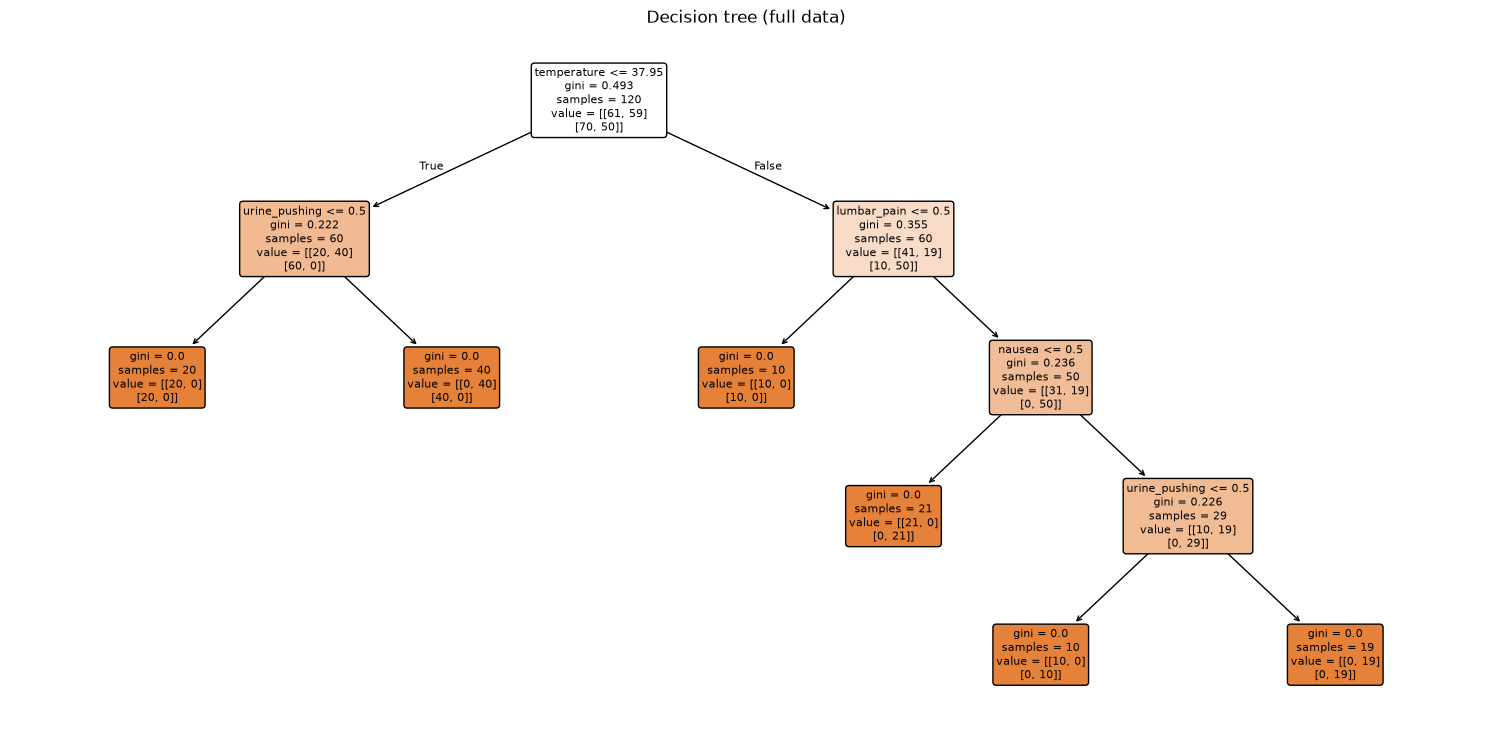

In [3]:
X1 = diagnosis[names[:6]]
y1 = diagnosis[names[6:]]
tree_full = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree_full.fit(X1, y1)
print('Training accuracy:', tree_full.score(X1,y1))
print('Leaves:', tree_full.get_n_leaves(), 'Depth:', tree_full.get_depth())
plt.figure(figsize=(19,9))
plot_tree(tree_full, feature_names=X1.columns, filled=True, rounded=True, fontsize=8)
plt.title('Decision tree (full data)')
plt.show()

### (c) IF-THEN rules

In [4]:
def print_rules(model, feature_names, label_names):
    t = model.tree_
    def walk(node, conditions):
        if t.feature[node] != -2:
            name = feature_names[t.feature[node]]
            threshold = t.threshold[node]
            walk(t.children_left[node], conditions + [f'{name} <= {threshold:.3f}'])
            walk(t.children_right[node], conditions + [f'{name} > {threshold:.3f}'])
        else:
            # For multi-output classification, each output has its own class counts.
            labels = []
            for j, label in enumerate(label_names):
                counts = t.value[node][j]
                labels.append(f'{label}={int(model.classes_[j][np.argmax(counts)])}')
            print('IF ' + (' AND '.join(conditions) if conditions else 'TRUE') + ' THEN ' + ', '.join(labels))
    walk(0, [])

print_rules(tree_full, list(X1.columns), list(y1.columns))

IF temperature <= 37.950 AND urine_pushing <= 0.500 THEN bladder_inflammation=0, renal_pelvis_nephritis=0
IF temperature <= 37.950 AND urine_pushing > 0.500 THEN bladder_inflammation=1, renal_pelvis_nephritis=0
IF temperature > 37.950 AND lumbar_pain <= 0.500 THEN bladder_inflammation=0, renal_pelvis_nephritis=0
IF temperature > 37.950 AND lumbar_pain > 0.500 AND nausea <= 0.500 THEN bladder_inflammation=0, renal_pelvis_nephritis=1
IF temperature > 37.950 AND lumbar_pain > 0.500 AND nausea > 0.500 AND urine_pushing <= 0.500 THEN bladder_inflammation=0, renal_pelvis_nephritis=1
IF temperature > 37.950 AND lumbar_pain > 0.500 AND nausea > 0.500 AND urine_pushing > 0.500 THEN bladder_inflammation=1, renal_pelvis_nephritis=1


### (d) Cost-complexity pruning

I use cross-validation to choose the pruning parameter. Among trees within one standard error of the best mean CV accuracy, I select the simplest tree.

,alpha,cv_accuracy,se,leaves
0,0.000000,1.000000,0.000000,6
1,0.049083,0.891667,0.044876,4
2,0.079472,0.783333,0.042492,3
3,0.111111,0.683333,0.055277,2
4,0.204236,0.391667,0.085999,1


Chosen alpha: 0.0 Leaves: 6 Train accuracy: 1.0


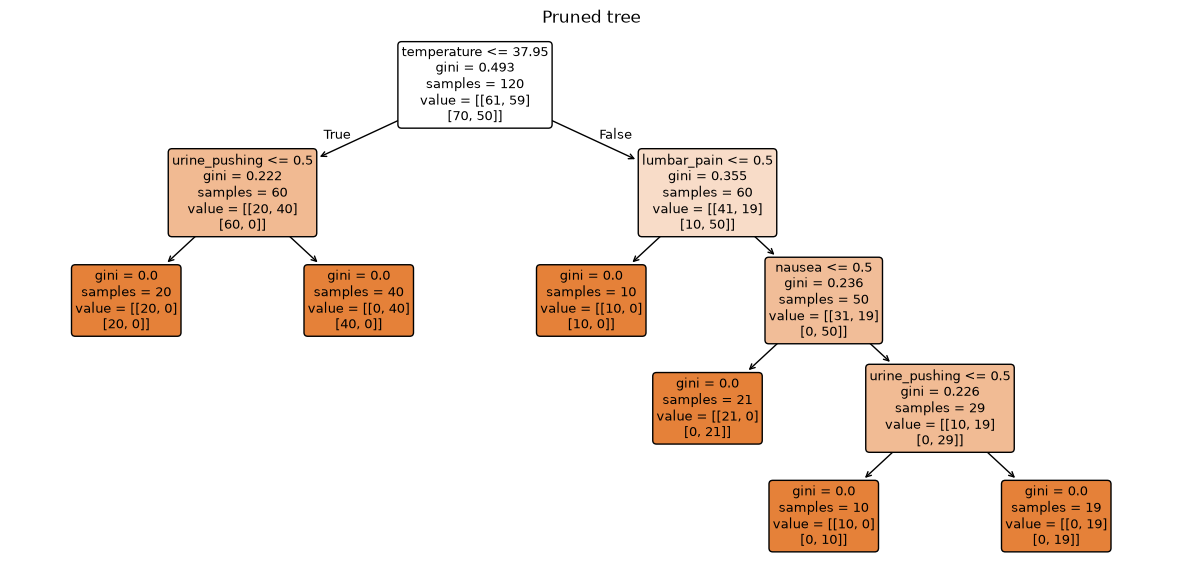

IF temperature <= 37.950 AND urine_pushing <= 0.500 THEN bladder_inflammation=0, renal_pelvis_nephritis=0
IF temperature <= 37.950 AND urine_pushing > 0.500 THEN bladder_inflammation=1, renal_pelvis_nephritis=0
IF temperature > 37.950 AND lumbar_pain <= 0.500 THEN bladder_inflammation=0, renal_pelvis_nephritis=0
IF temperature > 37.950 AND lumbar_pain > 0.500 AND nausea <= 0.500 THEN bladder_inflammation=0, renal_pelvis_nephritis=1
IF temperature > 37.950 AND lumbar_pain > 0.500 AND nausea > 0.500 AND urine_pushing <= 0.500 THEN bladder_inflammation=0, renal_pelvis_nephritis=1
IF temperature > 37.950 AND lumbar_pain > 0.500 AND nausea > 0.500 AND urine_pushing > 0.500 THEN bladder_inflammation=1, renal_pelvis_nephritis=1


In [5]:
path = tree_full.cost_complexity_pruning_path(X1,y1)
alphas = np.unique(path.ccp_alphas)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for alpha in alphas:
    model = DecisionTreeClassifier(ccp_alpha=float(alpha), random_state=RANDOM_STATE)
    scores = cross_val_score(model, X1, y1, cv=cv, scoring='accuracy')
    model.fit(X1,y1)
    rows.append((alpha, scores.mean(), scores.std(ddof=1)/np.sqrt(len(scores)), model.get_n_leaves()))
pruning = pd.DataFrame(rows,columns=['alpha','cv_accuracy','se','leaves'])
best = pruning.loc[pruning.cv_accuracy.idxmax()]
options = pruning[pruning.cv_accuracy >= best.cv_accuracy-best.se]
chosen = options.sort_values(['leaves','alpha'],ascending=[True,False]).iloc[0]
tree_small = DecisionTreeClassifier(ccp_alpha=float(chosen.alpha),random_state=RANDOM_STATE).fit(X1,y1)
display(pruning)
print('Chosen alpha:',chosen.alpha, 'Leaves:',tree_small.get_n_leaves(), 'Train accuracy:',tree_small.score(X1,y1))
plt.figure(figsize=(15,7))
plot_tree(tree_small, feature_names=X1.columns, filled=True, rounded=True, fontsize=9)
plt.title('Pruned tree')
plt.show()
print_rules(tree_small,list(X1.columns),list(y1.columns))

My pruning table shows that cross-validation accuracy is highest at alpha = 0 (1.0), and the 1-SE rule lets me pick any alpha whose CV accuracy is within one standard error of the best. The problem is that the best accuracy is 1.0 and its standard error is 0, so the only alpha that satisfies the rule is alpha = 0. Once I start pruning, accuracy drops right away: alpha = 0.049 gives 0.892, alpha = 0.079 gives 0.783, and it keeps going down from there.

I don't think this means the pruning step failed. The acute inflammations data only has 120 rows, and the four features (temperature, urine pushing, lumbar pain, nausea) separate the two diagnoses almost perfectly, so the full tree already does well under 5-fold CV. I could not find a simpler tree that keeps the same CV accuracy. The pruning table is still useful to me because it shows how much accuracy each simplification costs, and it tells me the full tree is the smallest tree the data actually supports, not just an arbitrary default.

## 2. LASSO and boosting for regression

### (a-b) Load data, split first 1495 rows, remove non-predictive fields and impute missing values

I fit the imputer only on the training data to avoid using information from the test set.

In [6]:
import re
lines = (DATA / 'communities.names').read_text(encoding='latin-1').splitlines()
columns = [re.match(r'@attribute\s+(\S+)',line,re.I).group(1) for line in lines if re.match(r'@attribute\s+(\S+)',line,re.I)]
crime = pd.read_csv(DATA / 'communities.data',header=None,names=columns,na_values='?')
print('Dataset:',crime.shape)
target = 'ViolentCrimesPerPop'
non_predictive = ['state','county','community','communityname','fold']
features = [c for c in crime.columns if c not in non_predictive+[target]]
X = crime[features].apply(pd.to_numeric,errors='coerce')
y = pd.to_numeric(crime[target],errors='coerce')
X_train_raw, X_test_raw = X.iloc[:1495], X.iloc[1495:]
y_train, y_test = y.iloc[:1495], y.iloc[1495:]
# Some columns can be completely empty in the training portion.
usable = X_train_raw.columns[X_train_raw.notna().any()].tolist()
X_train_raw, X_test_raw = X_train_raw[usable], X_test_raw[usable]
imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw),columns=usable,index=X_train_raw.index)
X_test = pd.DataFrame(imputer.transform(X_test_raw),columns=usable,index=X_test_raw.index)
print('Train/test:',X_train.shape,X_test.shape)
print('Missing after imputation:',X_train.isna().sum().sum(),X_test.isna().sum().sum())

Dataset: (1994, 128)
Train/test: (1495, 122) (499, 122)
Missing after imputation: 0 0


### (c) Correlation matrix

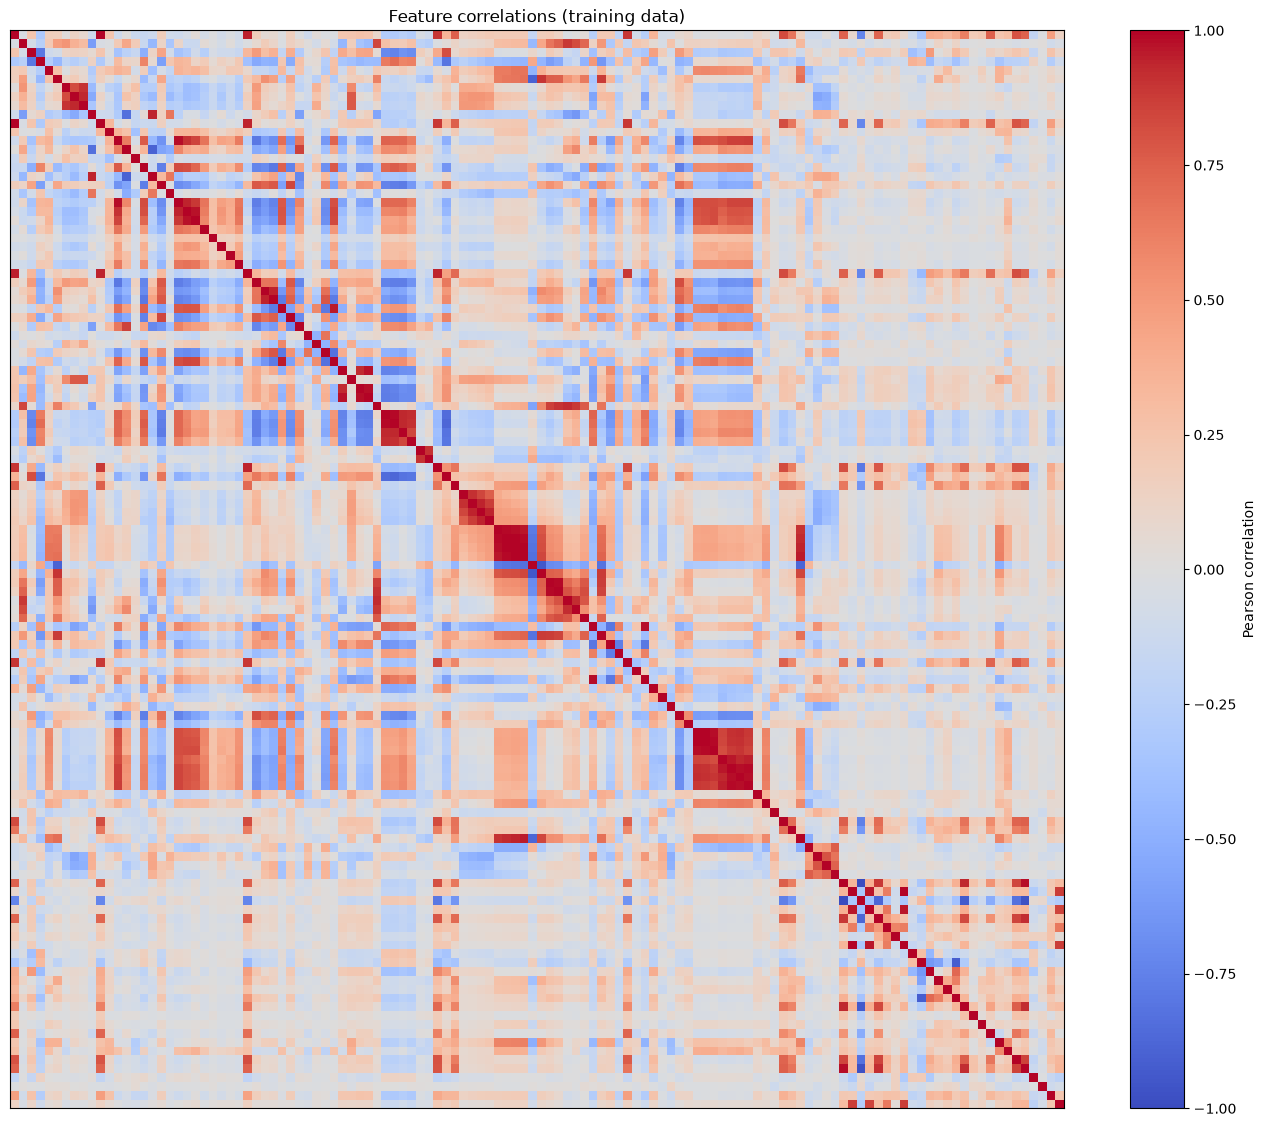

Many features are correlated, so regularization or dimension reduction may help.


In [7]:
corr = X_train.corr()
plt.figure(figsize=(17,14))
plt.imshow(corr,aspect='auto',cmap='coolwarm',vmin=-1,vmax=1)
plt.colorbar(label='Pearson correlation')
plt.title('Feature correlations (training data)')
plt.xticks([]); plt.yticks([])
plt.show()
print('Many features are correlated, so regularization or dimension reduction may help.')

### (d) Coefficient of variation

CV = sample standard deviation / mean. For zero means, CV is undefined.

In [8]:
cv_values = X_train.std(ddof=1) / X_train.mean().replace(0,np.nan)
cv_table = cv_values.rename('CV').sort_values(ascending=False)
display(cv_table.to_frame())

,CV
PctPolicAsian,5.527059
NumStreet,4.292923
NumInShelters,3.470952
NumIlleg,3.058964
NumImmig,2.926635
...,...
NumKindsDrugsSeiz,0.141021
RacialMatchCommPol,0.129652
PctPolicWhite,0.118727
LemasPctPolicOnPatr,0.112032


### (e) Top floor(sqrt(128)) features by CV: scatter plots and box plots

Selected: ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'LemasSwornFT', 'population', 'numbUrban', 'HousVacant']


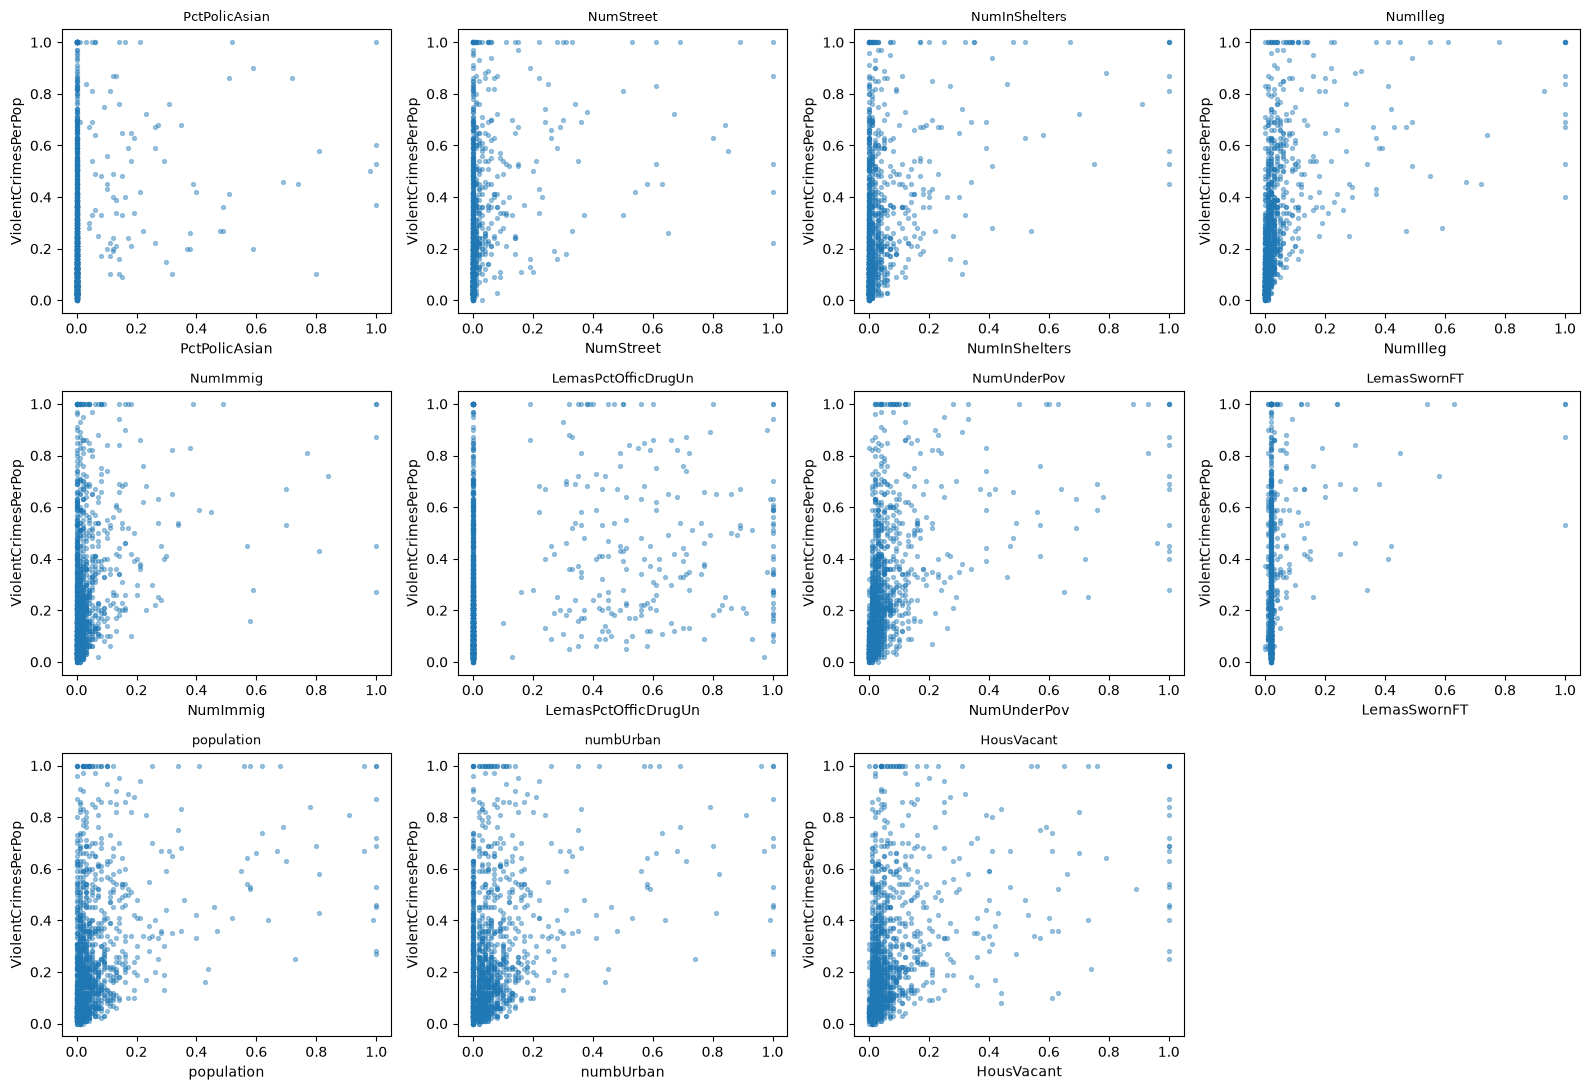

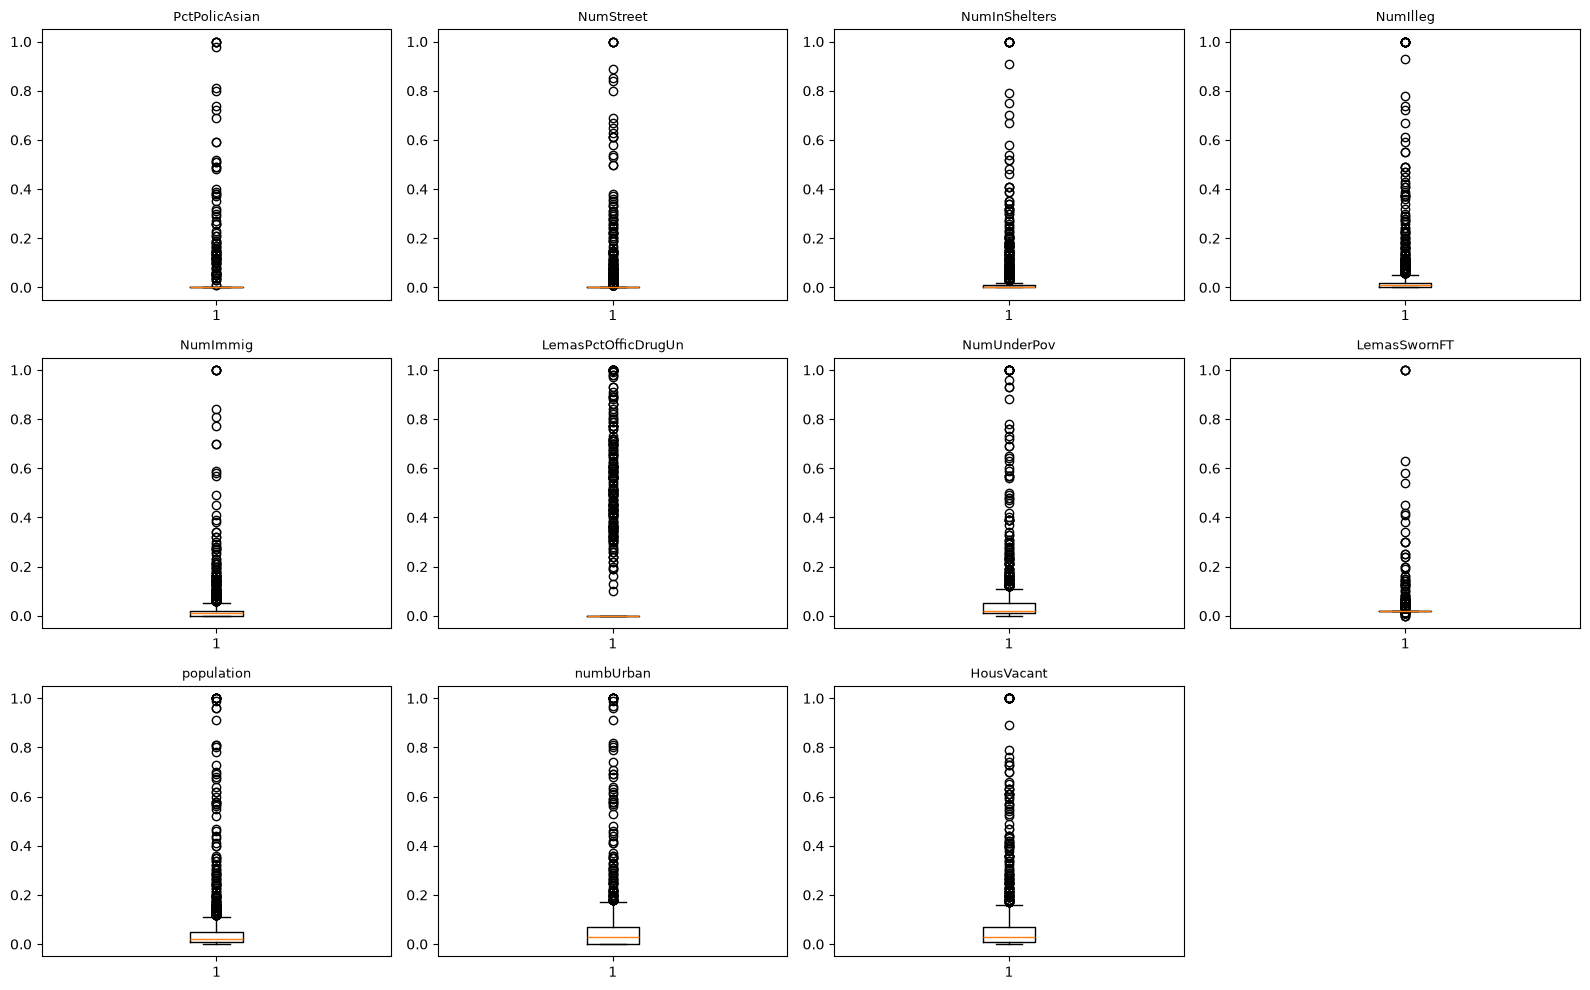

These plots show spread and possible relationships, but they cannot prove statistical significance on their own.


In [9]:
k = int(np.floor(np.sqrt(128)))
top = cv_table.replace([np.inf,-np.inf],np.nan).dropna().head(k).index.tolist()
print('Selected:',top)
fig, axes = plt.subplots(3,4,figsize=(16,11))
for ax, name in zip(axes.flat,top):
    ax.scatter(X_train[name],y_train,s=8,alpha=.4)
    ax.set_title(name,fontsize=9)
    ax.set_xlabel(name)
    ax.set_ylabel(target)
for ax in axes.flat[len(top):]: ax.axis('off')
plt.tight_layout();plt.show()
fig, axes = plt.subplots(3,4,figsize=(16,10))
for ax,name in zip(axes.flat,top):
    ax.boxplot(X_train[name].dropna())
    ax.set_title(name,fontsize=9)
for ax in axes.flat[len(top):]:ax.axis('off')
plt.tight_layout();plt.show()
print('These plots show spread and possible relationships, but they cannot prove statistical significance on their own.')

### (f-j) Regression models

I compare test mean squared error (MSE) for each model. The test set stays untouched during cross-validation.

In [10]:
results = {}
def report(name,pred):
    mse=mean_squared_error(y_test,pred)
    results[name]=mse
    print(f'{name}: test MSE = {mse:.6f}')

ols = LinearRegression().fit(X_train,y_train)
report('OLS',ols.predict(X_test))

OLS: test MSE = 0.017966


### (g) Ridge regression with cross-validation

In [11]:
folds=KFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
alpha_grid=np.logspace(-4,4,80)
ridge=RidgeCV(alphas=alpha_grid,cv=folds,scoring='neg_mean_squared_error').fit(X_train,y_train)
print('Best ridge alpha:',ridge.alpha_)
report('Ridge',ridge.predict(X_test))

Best ridge alpha: 3.605471154250506
Ridge: test MSE = 0.017464


### (h) LASSO with and without standardization

In [13]:
lasso=LassoCV(cv=folds,random_state=RANDOM_STATE,max_iter=30000,alphas=100).fit(X_train,y_train)
report('LASSO (original)',lasso.predict(X_test))
selected=pd.Series(lasso.coef_,index=usable)
print('LASSO alpha:',lasso.alpha_)
print('Selected features:',selected[selected.abs()>1e-8].index.tolist())

scaler=StandardScaler()
Xs_train=scaler.fit_transform(X_train)
Xs_test=scaler.transform(X_test)
lasso_scaled=LassoCV(cv=folds,random_state=RANDOM_STATE,max_iter=30000,alphas=100).fit(Xs_train,y_train)
report('LASSO (standardized)',lasso_scaled.predict(Xs_test))
selected_scaled=pd.Series(lasso_scaled.coef_,index=usable)
print('Scaled alpha:',lasso_scaled.alpha_)
print('Scaled selected features:',selected_scaled[selected_scaled.abs()>1e-8].index.tolist())
print('MSE difference (scaled - original):',results['LASSO (standardized)']-results['LASSO (original)'])

LASSO (original): test MSE = 0.017634
LASSO alpha: 0.00011614723626829858
Selected features: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShel

### (i) PCR: select number of components using cross-validation

Best M: 58
PCR: test MSE = 0.018385


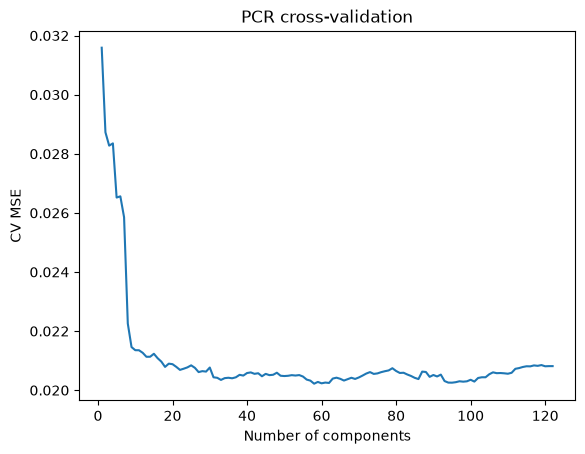

In [14]:
pcr_scores=[]
max_components=min(X_train.shape[1], X_train.shape[0] - X_train.shape[0]//5 - 1)
for m in range(1,max_components+1):
    pipe=Pipeline([('scale',StandardScaler()),('pca',PCA(n_components=m)),('reg',LinearRegression())])
    score=-cross_val_score(pipe,X_train,y_train,cv=folds,scoring='neg_mean_squared_error').mean()
    pcr_scores.append(score)
best_m=int(np.argmin(pcr_scores)+1)
pcr=Pipeline([('scale',StandardScaler()),('pca',PCA(n_components=best_m)),('reg',LinearRegression())]).fit(X_train,y_train)
print('Best M:',best_m)
report('PCR',pcr.predict(X_test))
plt.plot(range(1,len(pcr_scores)+1),pcr_scores)
plt.xlabel('Number of components');plt.ylabel('CV MSE');plt.title('PCR cross-validation');plt.show()

### (j) XGBoost: choose L1 regularization alpha by cross-validation

In [15]:
from xgboost import XGBRegressor
xgb=XGBRegressor(objective='reg:squarederror',n_estimators=300,max_depth=3,learning_rate=0.05,subsample=0.9,colsample_bytree=0.9,reg_lambda=1,random_state=RANDOM_STATE,n_jobs=2)
search=GridSearchCV(xgb,{'reg_alpha':[0,0.001,0.01,0.1,1,10,100]},cv=folds,scoring='neg_mean_squared_error',n_jobs=2)
search.fit(X_train,y_train)
print('Best XGBoost alpha:',search.best_params_['reg_alpha'])
report('XGBoost',search.predict(X_test))

Best XGBoost alpha: 0.1
XGBoost: test MSE = 0.016138


### Final comparison

In [16]:
comparison=pd.Series(results,name='Test MSE').sort_values().to_frame()
display(comparison)
print('Lowest test MSE:',comparison.index[0])
print('Note: A lower test MSE means better prediction on this particular test split.')

,Test MSE
XGBoost,0.016138
Ridge,0.017464
LASSO (original),0.017634
LASSO (standardized),0.017727
OLS,0.017966
PCR,0.018385


Lowest test MSE: XGBoost
Note: A lower test MSE means better prediction on this particular test split.
